In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("sales_dataset.csv")

df.head()

,Order_ID,Order_Date,Region,Category,Sub_Category,Units_Sold,Unit_Price,Discount,Sales,Profit
0,ORD-0734,2023-01-02,East,Office Supplies,Binders,7,217.53,0.10,1370.44,-78.35
1,ORD-0778,2023-01-02,North,Office Supplies,Labels,5,94.30,0.30,330.05,-14.89
2,ORD-0675,2023-01-04,West,Office Supplies,Paper,6,101.53,0.05,578.72,122.91
3,ORD-0725,2023-01-04,North,Technology,Machines,3,97.09,0.15,247.58,20.50
4,ORD-0694,2023-01-06,South,Technology,Phones,8,268.73,0.30,1504.89,-20.31


In [3]:
print("Shape of dataset:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
df.describe()

Shape of dataset:
(1200, 10)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order_ID      1200 non-null   str    
 1   Order_Date    1200 non-null   str    
 2   Region        1200 non-null   str    
 3   Category      1200 non-null   str    
 4   Sub_Category  1200 non-null   str    
 5   Units_Sold    1200 non-null   int64  
 6   Unit_Price    1188 non-null   float64
 7   Discount      1200 non-null   float64
 8   Sales         1176 non-null   float64
 9   Profit        1170 non-null   float64
dtypes: float64(4), int64(1), str(5)
memory usage: 93.9 KB

Statistical summary:


,Units_Sold,Unit_Price,Discount,Sales,Profit
count,1200.000000,1188.000000,1200.000000,1176.000000,1170.000000
mean,5.329167,223.017012,0.150458,1012.003435,75.394419
std,2.892425,126.218074,0.097817,850.366176,172.544088
min,1.000000,8.410000,0.000000,6.190000,-958.120000
25%,3.000000,114.740000,0.050000,326.815000,-1.092500
50%,5.000000,219.495000,0.150000,791.215000,33.085000
75%,8.000000,329.800000,0.250000,1454.552500,117.410000
max,10.000000,449.580000,0.300000,4440.700000,1079.150000


In [4]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Units_Sold"] = df["Units_Sold"].astype(int)

df["Unit_Price"] = pd.to_numeric(df["Unit_Price"], errors="coerce")
df["Discount"] = pd.to_numeric(df["Discount"], errors="coerce")
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Profit"] = pd.to_numeric(df["Profit"], errors="coerce")

df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month

df.head()

,Order_ID,Order_Date,Region,Category,Sub_Category,Units_Sold,Unit_Price,Discount,Sales,Profit,Year,Month
0,ORD-0734,2023-01-02,East,Office Supplies,Binders,7,217.53,0.10,1370.44,-78.35,2023,1
1,ORD-0778,2023-01-02,North,Office Supplies,Labels,5,94.30,0.30,330.05,-14.89,2023,1
2,ORD-0675,2023-01-04,West,Office Supplies,Paper,6,101.53,0.05,578.72,122.91,2023,1
3,ORD-0725,2023-01-04,North,Technology,Machines,3,97.09,0.15,247.58,20.50,2023,1
4,ORD-0694,2023-01-06,South,Technology,Phones,8,268.73,0.30,1504.89,-20.31,2023,1


In [5]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Order_ID         0
Order_Date       0
Region           0
Category         0
Sub_Category     0
Units_Sold       0
Unit_Price      12
Discount         0
Sales           24
Profit          30
Year             0
Month            0
dtype: int64


In [6]:
df["Unit_Price"] = df["Unit_Price"].fillna(df["Unit_Price"].mean())

df["Sales"] = df["Sales"].fillna(df["Sales"].mean())

df["Profit"] = df["Profit"].fillna(df["Profit"].mean())

print("Missing values after filling:")
print(df.isnull().sum())

Missing values after filling:
Order_ID        0
Order_Date      0
Region          0
Category        0
Sub_Category    0
Units_Sold      0
Unit_Price      0
Discount        0
Sales           0
Profit          0
Year            0
Month           0
dtype: int64


In [7]:
print("Total Sales:", df["Sales"].sum())

print("Total Profit:", df["Profit"].sum())

print("Average Sales:", df["Sales"].mean())

print("Total Units Sold:", df["Units_Sold"].sum())

Total Sales: 1214404.1224489796
Total Profit: 90473.30256410256
Average Sales: 1012.0034353741497
Total Units Sold: 6395


In [8]:
category_sales = df.groupby("Category")["Sales"].sum()

print("Sales by Category:")
print(category_sales)

region_sales = df.groupby("Region")["Sales"].sum()

print("\nSales by Region:")
print(region_sales)

sub_sales = df.groupby("Sub_Category")["Sales"].sum()

print("\nSales by Sub-Category:")
print(sub_sales) 

Sales by Category:
Category
Furniture          356545.710612
Office Supplies    459146.690918
Technology         398711.720918
Name: Sales, dtype: float64

Sales by Region:
Region
Central    236383.310306
East       250773.733435
North      261012.567483
South      179074.250612
West       287160.260612
Name: Sales, dtype: float64

Sales by Sub-Category:
Sub_Category
Accessories     85112.546871
Binders        122238.243741
Bookcases      126413.703435
Chairs          84586.533435
Copiers         97930.633435
Furnishings     83073.210306
Labels         115482.896871
Machines       115035.790306
Paper          110259.733435
Phones         100632.750306
Storage        111165.816871
Tables          62472.263435
Name: Sales, dtype: float64


In [9]:
monthly_sales = df.groupby(
    df["Order_Date"].dt.to_period("M")
)["Sales"].sum()

print(monthly_sales)

Order_Date
2023-01    33072.246871
2023-02    25657.010000
2023-03    40469.120000
2023-04    36919.790000
2023-05    23882.750000
2023-06    27679.473435
2023-07    27646.820000
2023-08    29867.513435
2023-09    34715.980000
2023-10    57098.580000
2023-11    27731.800000
2023-12    33143.723435
2024-01    43674.803435
2024-02    40679.480000
2024-03    36747.240000
2024-04    28920.690000
2024-05    21357.716871
2024-06    39101.600000
2024-07    42794.106871
2024-08    30750.133435
2024-09    39432.490000
2024-10    43233.690306
2024-11    26184.710000
2024-12    49141.653435
2025-01    17649.006871
2025-02    31570.760000
2025-03    42876.710000
2025-04    26207.190000
2025-05    29815.816871
2025-06    25850.620000
2025-07    29841.176871
2025-08    28061.153435
2025-09    24793.680000
2025-10    25289.210000
2025-11    39386.230000
2025-12    53159.446871
Freq: M, Name: Sales, dtype: float64


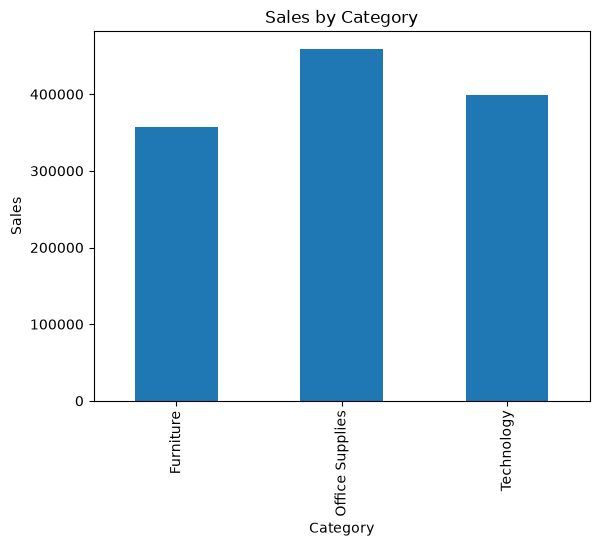

In [10]:
category_sales.plot(kind="bar")

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")

plt.show()

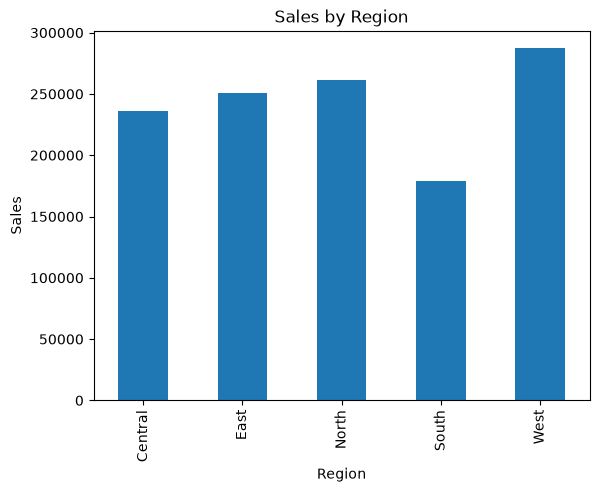

In [11]:
region_sales.plot(kind="bar")

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")

plt.show()

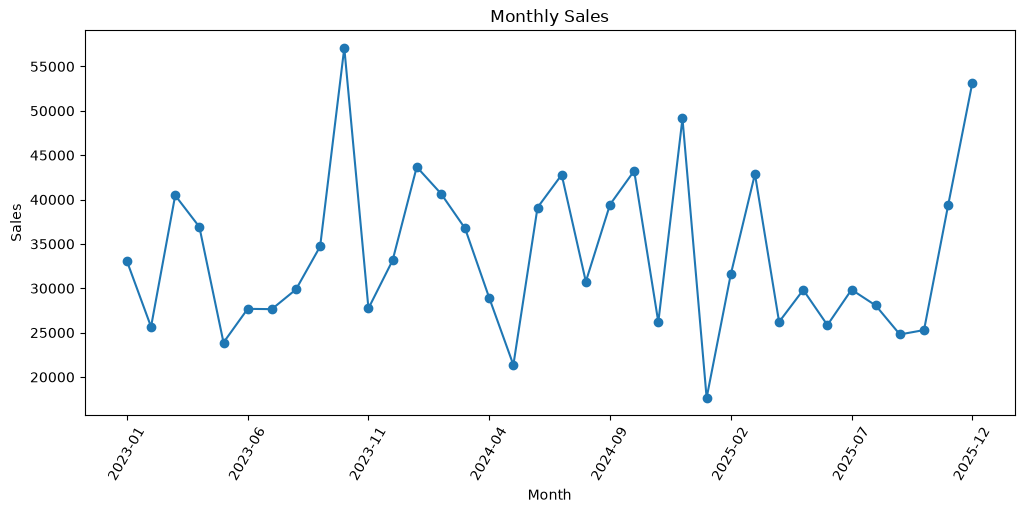

In [12]:
monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(kind="line", marker="o", figsize=(12, 5))

plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.xticks(rotation=60)
plt.show()

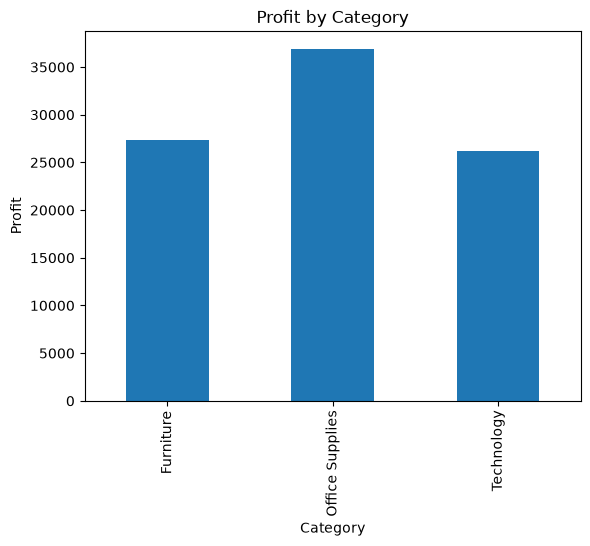

In [13]:
profit_category = df.groupby("Category")["Profit"].sum()

profit_category.plot(kind="bar")

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")

plt.show()

In [14]:
print("Highest Sales Category:", category_sales.idxmax())

print("Highest Sales Region:", region_sales.idxmax())

print("\nAnalysis completed successfully!")

Highest Sales Category: Office Supplies
Highest Sales Region: West

Analysis completed successfully!
